# Regression Discontinuity

**DS-UA 201: Causal Inference — Lab Notes**

Regression discontinuity designs (RDD) are one of the most credible tools in causal inference. They exploit something everywhere in real life: **rules with arbitrary cutoffs**.

---
## 1. The idea

Many things in life are governed by cutoffs that are, arguably, arbitrary:

- Score 90 or above and you get an A; score 89.9 and you get a B+.
- Get 50% + 1 of the vote and you win the election; get 49.9% and you lose.
- Turn 21 and you can legally drink; be 20 years and 364 days old and you can't.

People **just above** and **just below** a cutoff are treated differently, but otherwise they should be almost identical. Comparing them is like a small natural experiment right at the cutoff.

### The setup

We need three ingredients:

- A binary treatment $S \in \{0, 1\}$.
- A **running variable** $R$: usually a continuous variable measuring something about each person (a score, a vote share, an age).
- A **cutoff** $c$ that fully determines treatment:

$$S = \begin{cases} 1 & \text{if } R \geq c \\ 0 & \text{if } R < c \end{cases}$$

This is a **sharp** RDD: treatment switches on for *everyone* above the cutoff and *no one* below it. (The logic is identical if treatment is given *below* the cutoff instead.)

### Intuition: the effect of getting an A

Say we want the causal effect of getting an A in this class ($S$) on post-graduation income ($Y$).

The usual problem: $S \not\perp U$. Students who get A's could be harder-working, better at tests, or more interested in the subject. All of that is part of $U$ (other determinants of income) and is correlated with $S$, so comparing A students with everyone else is confounded.

But suppose grades are assigned by a rule on the final course score $R$, with $c = 90$. Students who score 89.5 and students who score 90 are basically the same. The difference between them is noise: how they felt on the day of the final, which slide they happened to revise. So comparing the incomes of students just above and just below 90 estimates the causal effect of an A (versus a B+).

### What this effect is (and isn't)

RDD estimates the effect **for people at the cutoff**:

$$\tau_{RD} = E[\,Y(S=1,U) - Y(S=0,U) \mid R = c\,]$$

It tells us nothing about what would happen if a student who scored 20 were magically given an A, or about the effect of an A on students who scored 100. They might differ in all sorts of ways.

Is that useful? Same answer as for the LATE: **it depends on the question**.

- *Should we lower the A cutoff slightly?* Yes: the affected students are exactly the ones near the cutoff.
- *What if we stopped giving A's entirely, including to the top scorers?* Not really: RDD says nothing about top scorers.

---
## 2. The identifying assumption: smoothness

The key assumption of RDD is that the two average potential outcome functions are **smooth (continuous) at the cutoff**:

$$E[\,Y(S=1,U) \mid R=r\,] \quad \text{and} \quad E[\,Y(S=0,U) \mid R=r\,] \quad \text{are smooth at } r=c$$

In words: as functions of the running variable, average outcomes don't do anything "funky" at the cutoff. Without the treatment, there would be no jump at $c$.

```
 E[Y]
  |                          ____ E[Y(1) | R=r]   <- observed to the right of c
  |                    ____/
  |               ___ /  ↑
  |         ____/     |  |  jump = τ_RD = E[Y(1) - Y(0) | R=c]
  |   ____/           |  ↓
  |  /                ●......  E[Y(0) | R=r]      <- observed to the left of c
  |_______________________|___________________ R
                          c
```

We only ever observe the top curve to the right of $c$ and the bottom curve to the left. Smoothness says that if the bottom curve were extended past $c$, it would carry on its path without a jump. So the observed jump at $c$ can only come from the treatment.

### Why this identifies the effect

**Right of the cutoff.** Everyone with $R \geq c$ is treated, so the observed average outcome *is* the treated potential outcome:

$$E[Y \mid R=c] = E[\,Y(S=1,U) \mid R=c\,]$$

**Left of the cutoff.** Nobody exactly at $c$ is untreated, so we can't observe $E[Y(S=0,U)\mid R=c]$ directly. Instead, we watch how untreated outcomes behave as $r$ *approaches* $c$ from below:

$$\lim_{r \uparrow c} E[Y \mid R=r] = \lim_{r \uparrow c} E[\,Y(S=0,U) \mid R=r\,] = E[\,Y(S=0,U) \mid R=c\,]$$

The first equality holds because everyone with $r < c$ is untreated. The second equality is **smoothness**: without continuity, the limit from below could differ from the value at $c$.

Subtracting the two:

$$\tau_{RD} = E[\,Y(S=1,U) - Y(S=0,U) \mid R=c\,] = E[Y\mid R=c] - \lim_{r\uparrow c} E[Y \mid R=r]$$

Both terms on the right are observable, so the causal effect at the cutoff is identified.

### What we are *not* assuming

We are not assuming that $R$ or $S$ is random. Characteristics can (and probably do) change on average with the running variable: students with higher scores really are different. We only assume nothing changes **suddenly** at $c$ except treatment.

**When it fails:** if something else also switches at the cutoff (say, A students also get a scholarship), or if people can precisely **manipulate** which side they land on (say, students who beg for an extra point to get from 89.5 to 90), then people just above and below are no longer comparable.

---
## 3. From theory to practice

The limit argument is airtight in theory but impossible to implement literally. We would need many people with scores of *exactly* 90, and many at 89, 89.5, 89.9, 89.99... to trace the limit. Real data never has that.

### Bandwidths

In practice, we use everyone within a **bandwidth** $b$ of the cutoff, i.e. with $R \in (c-b,\, c+b)$.

Choosing $b$ is a **bias–variance tradeoff**:

| | Small bandwidth (e.g. $b=1$: 89 vs 90) | Large bandwidth (e.g. $b=10$: 80s vs 90s) |
|---|---|---|
| Comparability | Very plausible that side of the cutoff is "as good as random" | Comparing 80s with 100s: much less plausible |
| Sample size | Tiny | Large |
| Result | **Less bias, more variance** | **More bias, less variance** |

Two ways to handle the choice:

1. **Optimal bandwidth selection.** Let an algorithm pick $b$ by minimising an estimate of mean squared error (bias² + variance). This guards against accusations of cherry-picking, though someone still chose what the algorithm optimises.
2. **Use several bandwidths** (the lo-fi but good option). Ideally the point estimates are similar across bandwidths, with larger bandwidths being more precise. That is the most convincing evidence that a result is real and not an artefact of one arbitrary choice.

### Local linear regression

Once we widen the window, we can't just compare mean outcomes on each side. The running variable *means* something, so outcomes trend with it. A simple difference in means would attribute that trend to the treatment.

Instead, assume the two outcome functions are approximately **linear** close to $c$, and estimate within the bandwidth:

$$Y = \alpha_0 + \alpha_1 S + \alpha_2 (R - c) + \alpha_3\, S \cdot (R - c) + \varepsilon$$

| Term | What it captures | Causal? |
|---|---|---|
| $\alpha_0$ | Predicted untreated outcome at the cutoff | No |
| $\alpha_1$ | **The jump at the cutoff, our estimate of $\tau_{RD}$** | **Yes** (under smoothness and a small enough bandwidth) |
| $\alpha_2$ | Slope of the line to the *left* of $c$ | No, just descriptive |
| $\alpha_2 + \alpha_3$ | Slope of the line to the *right* of $c$ | No, just descriptive |

Two details matter:

- **Centering.** We use $R - c$ instead of $R$. That way, $R - c = 0$ at the cutoff, so $\alpha_1$ is the gap between the two lines *exactly at* $c$. Without centering, $\alpha_1$ would be the gap at $R = 0$ (a vote share of 0, or a score of 0), which is meaningless.
- **Separate slopes.** The interaction $S\cdot(R-c)$ lets the slope differ on each side, so we don't force both sides to share one line.

We can also add higher-order terms, $(R-c)^2$ and $S\cdot(R-c)^2$, to allow curvature. With a small bandwidth this should make little difference, so adding a quadratic is a good **robustness check**: if the answer moves a lot, the linear approximation is struggling.

---
## 4. Worked example: incumbency advantage

Political scientists have long argued that **incumbents** (people who currently hold office) have a built-in advantage at the next election. How large is it?

- $Y$: a party's vote share in the **current** election.
- $S = 1$ if the party is the **incumbent** (it won the previous election).
- $U$: other determinants of vote share.

The naive comparison is badly confounded: $S \not\perp U$. Popular parties are more likely to have won last time *and* to do well this time, so incumbents would do better even without any incumbency advantage.

Elections offer a natural sharp RDD (Lee 2008):

- $R$: the party's vote share in the **previous** election.
- $c = 0.5$: win with more than 50%, lose with less.

A party that won last time with 50.2% and one that lost with 49.8% are about equally popular; which side they ended up on is close to a coin flip. Comparing how they do *this* time isolates the effect of incumbency.

### Our data

Here we **simulate** data that mimics the lecture's data to know the true answer, so we can check whether each method recovers it. Variable names follow the lecture:

| Column | Meaning |
|---|---|
| `share` | Vote share in the previous election (running variable $R$) |
| `inc` | 1 if the party won last time (treatment $S$) |
| `next` | Vote share in the current election (outcome $Y$) |
| `experience` | Years of political experience (a pre-determined characteristic, used to test smoothness) |

**The true incumbency advantage at the cutoff is 0.06**, i.e. 6 percentage points of vote share for parties that barely won.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from scipy import stats

BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#8a8a8a"

In [2]:
def make_elections(n=6_000, manipulation=0.0, seed=2008):
    rng = np.random.default_rng(seed)

    popularity = rng.normal(0, 1, n)
    share = np.clip(0.5 + 0.06 * popularity + 0.09 * rng.normal(0, 1, n), 0.02, 0.98)

    if manipulation > 0:
        could_cheat = (share >= 0.46) & (share < 0.5) & (popularity > 0.5)
        cheats = could_cheat & (rng.uniform(size=n) < manipulation)
        share[cheats] = rng.uniform(0.5, 0.51, cheats.sum())

    inc = (share >= 0.5).astype(int)
    experience = rng.poisson(np.exp(1.6 + 0.35 * popularity)).astype(float)

    x = share - 0.5
    y0 = 0.43 + 0.22 * np.tanh(5 * x) + 0.03 * popularity + rng.normal(0, 0.05, n)
    y1 = y0 + 0.06 + 0.15 * x
    next_share = np.clip(np.where(inc == 1, y1, y0), 0, 1)

    return pd.DataFrame({"share": share, "inc": inc, "next": next_share, "experience": experience})


ld = make_elections()
ld.head()

,share,inc,next,experience
0,0.531146,1,0.492038,0.0
1,0.434504,0,0.312466,3.0
2,0.599324,1,0.691049,7.0
3,0.462336,0,0.392100,2.0
4,0.538839,1,0.502256,5.0


**Code explained**

- `popularity` is the unobserved confounder (part of $U$). It drives **both** last election's vote share (`share`) and this election's (`y0`), which is what makes the naive comparison biased. It is *not* returned in the final DataFrame, because a researcher wouldn't observe it.
- `inc = (share >= 0.5).astype(int)` is the **sharp** rule: winning is entirely determined by whether the running variable crosses 0.5.
- `experience` depends on popularity, so it trends smoothly with `share`, but nothing about it jumps at 0.5. It plays the role of an observable "component of $U$".
- `y0` is the vote share a party would get **without** incumbency. `np.tanh(5 * x)` makes it an S-shaped, smooth function of last time's vote share: parties that won big last time tend to do well again, but with diminishing returns. Crucially, it is **smooth at 0.5**: that is the RDD assumption built in.
- `y1 = y0 + 0.06 + 0.15 * x` adds the incumbency effect. At the cutoff ($x = 0$) it is exactly **0.06**. Away from the cutoff it differs (larger for big winners), which is why RDD only identifies the effect **at** $c$.
- `manipulation` is off (0) for now. Section 4.2 switches it on to show what a broken design looks like: some popular candidates who were about to lose narrowly "find" just enough votes to land just above 50%.

### 4.1 Step 1: confirm the discontinuity is really sharp

Before anything else, check in the data that treatment actually jumps from 0 to 1 at the cutoff. If some parties below 50% were incumbents (or vice versa), we would have a fuzzy design instead (Section 5).

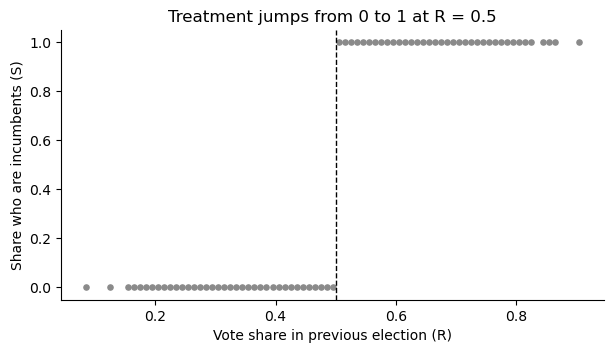

In [3]:
ld["share_bin"] = (ld["share"] // 0.01) * 0.01 + 0.005
win_by_bin = ld.groupby("share_bin")["inc"].mean()

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.scatter(win_by_bin.index, win_by_bin.values, s=14, color=GREY)
ax.axvline(0.5, color="black", linestyle="--", linewidth=1)
ax.set(xlabel="Vote share in previous election (R)", ylabel="Share who are incumbents (S)",
       title="Treatment jumps from 0 to 1 at R = 0.5")
ax.spines[["top", "right"]].set_visible(False)
plt.show()

**Code explained**

- `(ld["share"] // 0.01) * 0.01 + 0.005` puts each election into a 1-percentage-point bin and labels the bin by its midpoint. `//` is floor division, so 0.4973 becomes bin 0.495 (covering 0.49 to 0.50).
- `groupby("share_bin")["inc"].mean()` gives the share of incumbents in each bin. This "binning, then averaging" idea is called a **bin scatter**, and it is the standard way to visualise RDD data: the raw points are too noisy to see anything.

The plot is a perfect step: 0 everywhere below 0.5, 1 everywhere above. The design is sharp.

### 4.2 Step 2: test the assumptions

Smoothness can't be tested directly, because it is about potential outcomes we never see. But it has two checkable implications.

#### (a) Pre-determined characteristics should be smooth at the cutoff

The smoothness assumption is about averages taken over $U$, so in effect it requires that **the other characteristics of candidates don't change suddenly at $c$**. We can't see all of $U$, but we can check the parts we observe. Lee checks **political experience**: it plausibly affects electoral success, and it was determined *before* the election, so incumbency can't have caused it.

The test: run the same local linear regression, with the characteristic as the "outcome". The coefficient on `inc` should be close to 0 and insignificant. We also check it visually.

The two functions below are used for the rest of the notebook: one runs the RDD regression, the other draws the RDD plot.

In [4]:
def rd_estimate(df, outcome, b, quadratic=False):
    d = df[(df["share"] - 0.5).abs() < b].copy()
    d["Rminusc"] = d["share"] - 0.5
    d["SRminusc"] = d["inc"] * d["Rminusc"]
    formula = f"{outcome} ~ inc + Rminusc + SRminusc"

    if quadratic:
        d["Rminusc2"] = d["Rminusc"] ** 2
        d["SRminusc2"] = d["inc"] * d["Rminusc2"]
        formula += " + Rminusc2 + SRminusc2"

    return smf.ols(formula, data=d).fit(cov_type="HC0")

**Code explained**

This is the local linear regression from Section 3, written once so we can reuse it.

- `df[(df["share"] - 0.5).abs() < b]` applies the **bandwidth**: keep only elections where last time's vote share was within $b$ of 50%. `.copy()` makes a separate table, so adding columns doesn't touch the original.
- `Rminusc` is the **centred** running variable $R - c$, and `SRminusc` is the interaction $S \cdot (R-c)$, which lets the slope differ on each side. Same names as in the lecture code.
- `formula = f"{outcome} ~ inc + Rminusc + SRminusc"` writes $Y = \alpha_0 + \alpha_1 S + \alpha_2(R-c) + \alpha_3 S(R-c)$. The f-string slots in whichever outcome we pass (`"next"` or `"experience"`). The coefficient on `inc` is $\alpha_1$, the jump at the cutoff.
- With `quadratic=True`, the function adds $(R-c)^2$ and $S\cdot(R-c)^2$, allowing a curve on each side instead of a straight line.
- `.fit(cov_type="HC0")` uses **heteroskedasticity-robust standard errors**, as in the lecture. The spread of vote shares around the line differs along the running variable, and ordinary standard errors would assume it is constant.

In [5]:
def rd_plot(df, outcome, b, ax, bin_width=0.01, window=0.25):
    view = df[(df["share"] - 0.5).abs() < window]
    bins = (view["share"] // bin_width) * bin_width + bin_width / 2
    binned = view.groupby(bins)[outcome].mean()
    ax.scatter(binned.index, binned.values, s=14, color=GREY, zorder=2)

    fit = rd_estimate(df, outcome, b)
    a0, a1, a2, a3 = fit.params[["Intercept", "inc", "Rminusc", "SRminusc"]]
    left = np.linspace(0.5 - b, 0.5, 50)
    right = np.linspace(0.5, 0.5 + b, 50)
    ax.plot(left, a0 + a2 * (left - 0.5), color=ORANGE, linewidth=2.5, label="Lost last time (S = 0)")
    ax.plot(right, a0 + a1 + (a2 + a3) * (right - 0.5), color=BLUE, linewidth=2.5, label="Won last time (S = 1)")

    ax.axvline(0.5, color="black", linestyle="--", linewidth=1)
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(frameon=False, loc="upper left")
    return fit

**Code explained**

The first block is the same bin scatter as before, restricted to a window of ±0.25 around the cutoff so the plot isn't dominated by landslides.

The second block draws the fitted regression lines, which is where the coefficients' meaning becomes visible:

- `fit.params[["Intercept", "inc", "Rminusc", "SRminusc"]]` pulls out $\alpha_0, \alpha_1, \alpha_2, \alpha_3$.
- **Left line** (losers, $S=0$): $\alpha_0 + \alpha_2(R-c)$. Starts at $\alpha_0$ at the cutoff with slope $\alpha_2$.
- **Right line** (winners, $S=1$): $(\alpha_0 + \alpha_1) + (\alpha_2+\alpha_3)(R-c)$. Starts at $\alpha_0 + \alpha_1$ with slope $\alpha_2 + \alpha_3$.
- So the vertical gap between the two lines **at exactly 0.5** is $\alpha_1$, the RDD estimate. Each line only spans the bandwidth it was estimated on.

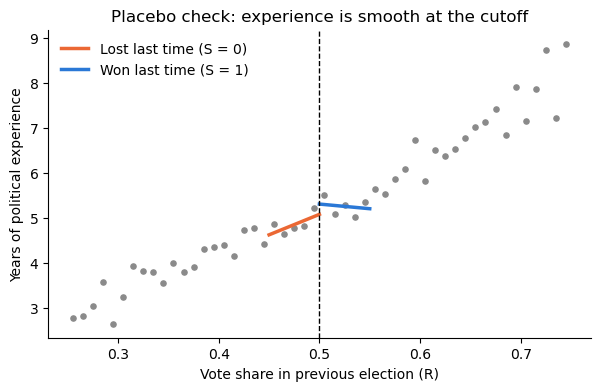

b = 0.01  jump in experience = +0.61 years  (SE 0.56, p = 0.28, n = 408)
b = 0.05  jump in experience = +0.23 years  (SE 0.25, p = 0.37, n = 2099)


In [6]:
fig, ax = plt.subplots(figsize=(7, 4))
exp_fit = rd_plot(ld, "experience", b=0.05, ax=ax)
ax.set(xlabel="Vote share in previous election (R)", ylabel="Years of political experience",
       title="Placebo check: experience is smooth at the cutoff")
plt.show()

for b in [0.01, 0.05]:
    fit = rd_estimate(ld, "experience", b)
    print(f"b = {b:<5} jump in experience = {fit.params['inc']:+.2f} years  (SE {fit.bse['inc']:.2f}, p = {fit.pvalues['inc']:.2f}, n = {int(fit.nobs)})")

**Reading the result.** Experience rises steadily with vote share (more popular parties field more experienced candidates), but there is **no meaningful jump at 0.5**: the two lines nearly meet, and the estimated discontinuity is small and statistically insignificant at both bandwidths (the visible gap is noise). Good news for the design.

The same caveat as any balance test applies: this rules out jumps in **observable** characteristics only. Unobservables could still jump. But we can check for one important *source* of jumps in unobservables: manipulation.

#### (b) No bunching: nobody should be able to sort themselves across the cutoff

Smoothness is in trouble if people can **manipulate the running variable**, i.e. choose to land just above the cutoff.

Imagine very popular candidates could spend just enough money and effort to get just over 50%, winning without wasting resources. Then the elections just above 0.5 would be full of highly popular candidates who are **not comparable** to those just below.

If that were happening, we would see it in the data: a **bunch** (a disproportionate number of observations) just above the cutoff, and a dip just below. So we check the *density* of the running variable around $c$.

To see what a failure looks like, we compare our data with a manipulated version where 60% of popular near-losers "find" enough votes to scrape a win.

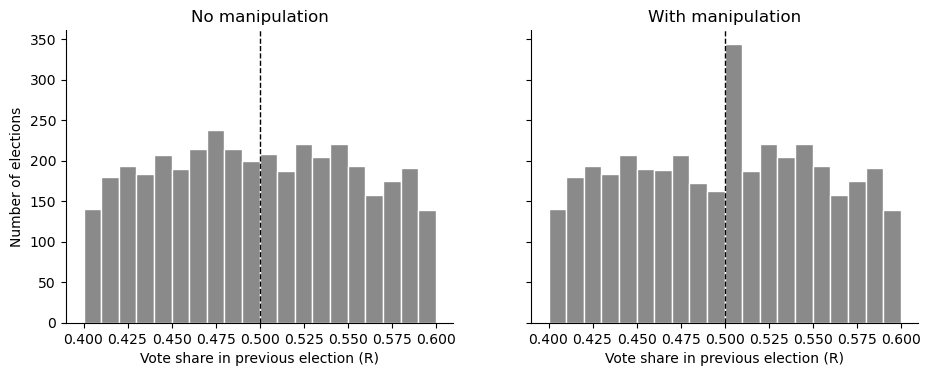

No manipulation    just below:  200   just above:  208   p = 0.729
With manipulation  just below:  163   just above:  344   p = 6.44e-16


In [7]:
ld_cheat = make_elections(manipulation=0.6)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
bin_edges = np.arange(0.40, 0.60 + 1e-9, 0.01)
for ax, data, title in [(axes[0], ld, "No manipulation"), (axes[1], ld_cheat, "With manipulation")]:
    ax.hist(data["share"], bins=bin_edges, color=GREY, edgecolor="white")
    ax.axvline(0.5, color="black", linestyle="--", linewidth=1)
    ax.set(title=title, xlabel="Vote share in previous election (R)")
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("Number of elections")
plt.show()

for name, data in [("No manipulation", ld), ("With manipulation", ld_cheat)]:
    below = ((data["share"] >= 0.49) & (data["share"] < 0.50)).sum()
    above = ((data["share"] >= 0.50) & (data["share"] < 0.51)).sum()
    p = stats.binomtest(above, below + above, 0.5).pvalue
    print(f"{name:<18} just below: {below:>4}   just above: {above:>4}   p = {p:.3g}")

**Code explained**

- `ld_cheat = make_elections(manipulation=0.6)` builds the same population, except that 60% of candidates who were popular and narrowly losing (46–50%) get moved to 50–51%.
- `ax.hist(..., bins=bin_edges)` draws the number of elections in each 1-point bin. In clean data the histogram should flow smoothly through 0.5.
- The bunching test counts elections in the bin just below (49–50%) and just above (50–51%). If nobody can manipulate, landing just above or just below is close to a coin flip, so each election in the window should be ~50/50.
- `stats.binomtest(above, below + above, 0.5)` tests exactly that: out of `below + above` elections, is the number above consistent with a 50% chance? A tiny p-value means the split is too lopsided to be chance.

**Reading the result.** The clean data shows no spike, and the split is balanced (large p-value): no evidence that candidates choose which side they land on. The manipulated data shows an obvious spike in the bin just above 0.5 (and a slight dip in the bins below, where the cheaters came from), and the test rejects decisively.

This simple version is enough for intuition. The formal version, the **McCrary density test** (or the `rddensity` package), fits the density smoothly on each side and tests for a jump, but the logic is identical.

In [8]:
for name, data in [("No manipulation", ld), ("With manipulation", ld_cheat)]:
    exp_jump = rd_estimate(data, "experience", 0.02)
    vote_jump = rd_estimate(data, "next", 0.02)
    print(f"{name:<18} jump in experience: {exp_jump.params['inc']:+.2f} (p = {exp_jump.pvalues['inc']:.3f})   "
          f"incumbency estimate: {vote_jump.params['inc']:.3f}")

No manipulation    jump in experience: +0.12 (p = 0.765)   incumbency estimate: 0.062
With manipulation  jump in experience: +1.91 (p = 0.000)   incumbency estimate: 0.085


**Why bunching matters.** With manipulation, the candidates just above 0.5 are disproportionately popular, so (i) experience now **jumps** at the cutoff, failing the placebo check, and (ii) the incumbency estimate is **inflated** above the true 0.06, because some of the popularity advantage is credited to incumbency. The two tests catch exactly the problem that would bias the estimate.

From here on we use the clean data, `ld`.

### 4.3 Step 3: estimate the incumbency advantage

Assumptions look good, so we estimate. First, the naive comparison, to see how much confounding RDD removes:

In [9]:
naive = ld.loc[ld["inc"] == 1, "next"].mean() - ld.loc[ld["inc"] == 0, "next"].mean()
print(f"Naive difference (all incumbents vs all challengers): {naive:.3f}")

Naive difference (all incumbents vs all challengers): 0.264


The naive gap is about **0.26**, more than four times the true effect. It compares landslide winners with landslide losers, so it mostly measures the difference in popularity.

Now the RDD, with the same two bandwidths as the lecture:

- $b = 0.01$: elections decided between 49% and 51%. Very credible comparison, small sample.
- $b = 0.05$: elections decided between 45% and 55%. Slightly less credible, much bigger sample.

In [10]:
small_b = rd_estimate(ld, "next", b=0.01)
small_b.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                   next   R-squared:                       0.312
Model:                            OLS   Adj. R-squared:                  0.306
Method:                 Least Squares   F-statistic:                     64.98
Date:                Fri, 13 Nov 2026   Prob (F-statistic):           2.64e-34
Time:                        00:39:38   Log-Likelihood:                 583.58
No. Observations:                 408   AIC:                            -1159.
Df Residuals:                     404   BIC:                            -1143.
Df Model:                           3                                         
Covariance Type:                  HC0                                         
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      0.4344      0.010     45.609      0.000       0.416       0.453
inc            0.0594      0.012      4.908      0.000       0.036       0.083
Rminusc        2.2897      1.550      1.477      0.140      -0.748       5.327
SRminusc      -0.9951      2.007     -0.496      0.620      -4.928       2.938
==============================================================================
Omnibus:                        8.847   Durbin-Watson:                   2.176
Prob(Omnibus):                  0.012   Jarque-Bera (JB):                8.912
Skew:                           0.316   Prob(JB):                       0.0116
Kurtosis:                       3.352   Cond. No.                         903.
==============================================================================

Notes:
[1] Standard Errors are heteroscedasticity robust (HC0)
"""

**Reading the regression table** (the row that matters is `inc`):

- `inc` ≈ **0.06**: parties that barely won last time get about 6 percentage points more of the vote this time than parties that barely lost. This is $\alpha_1$, the incumbency advantage at the cutoff.
- `Rminusc` ($\alpha_2$) and `SRminusc` ($\alpha_3$) describe the slopes on each side. They are imprecise here because the window is so narrow, and they **have no causal interpretation** either way. They are controls that soak up the trend in the running variable.
- `Intercept` ($\alpha_0$) is the predicted vote share of a party that *just* lost: roughly 43%.
- "Covariance Type: HC0" confirms robust standard errors.

In [ ]:
big_b = rd_estimate(ld, "next", b=0.05)

for label, fit in [("b = 0.01", small_b), ("b = 0.05", big_b)]:
    low, high = fit.conf_int().loc["inc"]
    print(f"{label}: estimate {fit.params['inc']:.3f}, SE {fit.bse['inc']:.4f}, "
          f"95% CI [{low:.3f}, {high:.3f}], n = {int(fit.nobs)}")

**Reading the result.** The two bandwidths give very similar estimates (≈ 0.059 and ≈ 0.063, close to the true 0.06, and close to the lecture's real-data estimates of 0.054 and 0.062). Both are significant, and the larger bandwidth is more precise: five times the sample, less than half the standard error.

**Interpretation:** there is an incumbency advantage of about 6 percentage points **for parties that barely won their last election**. RDD tells us nothing about the advantage for parties that won by a landslide, or about what incumbency would do for parties that lost badly. (In this simulation the effect is in fact larger for big winners, and RDD rightly doesn't claim to see that.)

### 4.4 Step 4: robustness across bandwidths and functional forms

Two of our choices were arbitrary: the bandwidth, and fitting straight lines. A credible result shouldn't depend on either, so we re-estimate across a range of bandwidths, three ways each:

1. **Difference in means** within the bandwidth (no adjustment for the running variable).
2. **Local linear** (our main specification).
3. **Local quadratic** (adds curvature).

In [11]:
rows = []
for b in [0.01, 0.025, 0.05, 0.10, 0.20, 0.50]:
    window = ld[(ld["share"] - 0.5).abs() < b]
    diff_means = window.loc[window["inc"] == 1, "next"].mean() - window.loc[window["inc"] == 0, "next"].mean()
    linear = rd_estimate(ld, "next", b)
    quad = rd_estimate(ld, "next", b, quadratic=True)
    rows.append({"bandwidth": b, "n": int(linear.nobs), "diff in means": diff_means,
                 "local linear": linear.params["inc"], "linear SE": linear.bse["inc"],
                 "local quadratic": quad.params["inc"], "quadratic SE": quad.bse["inc"]})

pd.DataFrame(rows).set_index("bandwidth").round(3)

,n,diff in means,local linear,linear SE,local quadratic,quadratic SE
bandwidth,,,,,,
0.010,408,0.077,0.059,0.012,0.060,0.019
0.025,1019,0.094,0.063,0.007,0.061,0.012
0.050,2099,0.127,0.063,0.005,0.060,0.008
0.100,3861,0.183,0.062,0.004,0.065,0.005
0.200,5649,0.247,0.077,0.003,0.056,0.004
0.500,6000,0.264,0.090,0.003,0.059,0.003


**Reading the table** (true effect: 0.06):

- **Difference in means is biased, and the bias grows with the bandwidth.** It ignores that vote share trends upward with last time's vote share, so the trend gets counted as incumbency. Even at $b=0.01$ it overshoots, and at $b=0.5$ it is basically the naive estimate. This is why we control for $R - c$.
- **Local linear is stable for small to moderate bandwidths** (0.01 to 0.10, all ≈ 0.06), with standard errors shrinking as $n$ grows. This is the bias–variance tradeoff working in our favour.
- **At wide bandwidths, local linear drifts upward** (≈ 0.08 at $b = 0.2$, ≈ 0.09 at $b = 0.5$). The outcome curve bends, so a straight line fitted over a wide window misses the value at the cutoff. Note the tiny standard errors: the estimate is precise but **wrong**. More data cannot fix bias.
- **Local quadratic stays near 0.06 everywhere,** because it can follow the curve. At small bandwidths it is noisier than linear (more parameters, same data), which is why linear is the default, and quadratic is the robustness check.

The lesson: report several bandwidths and both specifications. Agreement within the credible range (here, $b \leq 0.10$) is what makes the result convincing.

### 4.5 Step 5: visualise the result

RDD results lend themselves to a clean picture: a bin scatter of the raw data with the fitted lines on each side. The jump at the cutoff *is* the estimate.

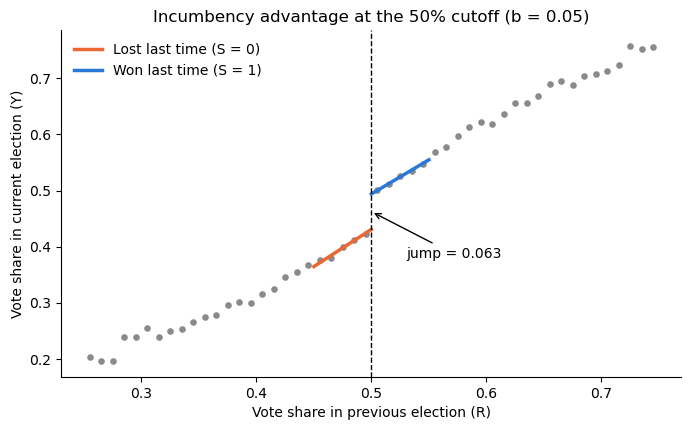

In [12]:
fig, ax = plt.subplots(figsize=(8, 4.5))
fit = rd_plot(ld, "next", b=0.05, ax=ax)
ax.annotate(f"jump = {fit.params['inc']:.3f}", xy=(0.5, fit.params["Intercept"] + fit.params["inc"] / 2),
            xytext=(0.53, 0.38), arrowprops=dict(arrowstyle="->", color="black"))
ax.set(xlabel="Vote share in previous election (R)", ylabel="Vote share in current election (Y)",
       title="Incumbency advantage at the 50% cutoff (b = 0.05)")
plt.show()

The grey dots show the outcome rising smoothly with last election's vote share on both sides, with one clear break at 0.5. The orange and blue lines are the local linear fit within the bandwidth, and the gap between them at the dashed line is the estimated incumbency advantage.

---
## 5. Fuzzy RDD

### The idea

In a sharp RDD, crossing the cutoff **always** switches treatment on. Often, though, crossing the cutoff only makes treatment **more likely**.

**Example (Mountjoy 2025):** Texas public universities have internal SAT cutoffs, but they also weigh high school grades, extracurriculars and so on. Scoring above the cutoff raises your chance of getting in and enrolling; it doesn't guarantee it. So:

$$S \neq \begin{cases} 1 & \text{if } R \geq c \\ 0 & \text{if } R < c \end{cases}$$

What we need instead is that the **probability** of treatment jumps at the cutoff:

$$P(S = 1 \mid R = r) \text{ jumps discretely at } r = c$$

That is a **fuzzy RDD**. A sharp RDD is the special case where the probability jumps all the way from 0 to 1.

### Fuzzy RDD is IV

Right around the cutoff, students just above and just below are basically the same, except that those above are more likely to be treated. So being above the cutoff is as good as random **and** shifts treatment: it is an **instrument**.

$$Z = \begin{cases} 1 & \text{if } R \geq c \\ 0 & \text{if } R < c \end{cases}$$

Check the LATE assumptions (IV assumptions), comparing a student who scored 1,000 (just above a cutoff of 1,000) with one who scored 990:

| Assumption | Statement | Does it hold here? |
|---|---|---|
| **Relevance** | $S(Z=1,V) \neq S(Z=0,V)$ for some people | Yes, as long as the cutoff has *some* influence on admissions. Checkable: the jump in $P(S=1)$. |
| **Monotonicity** | $S(Z=1,V) \geq S(Z=0,V)$ for everyone | Usually very plausible: being above the cutoff is never *bad* for your admission. |
| **Exogeneity** | $Z \perp U, V$ | Plausible right at the cutoff: 1,000 vs 990 is essentially noise. |

Because we use a bandwidth (not just people exactly at the cutoff), we control for $(R-c)$ and its interaction with $Z$, as in the sharp case. So what we really need is exogeneity **conditional** on those controls. That holds if, within the bandwidth, average outcomes **and** treatment probabilities are approximately linear in $R$ on each side.

In plain words: the "type" of person shouldn't change suddenly at the cutoff. We test that **exactly as in the sharp case**: smoothness of pre-determined characteristics, and no bunching.

### What it estimates

The same Wald logic as IV, measured at the cutoff:

$$\tau_{\text{fuzzy}} = \frac{\text{jump in } E[Y \mid R] \text{ at } c}{\text{jump in } P(S=1 \mid R) \text{ at } c} = \frac{\text{reduced form}}{\text{first stage}}$$

This is a **LATE** that is local in *two* ways:

$$E[\,Y(S=1,U) - Y(S=0,U) \mid R = c,\ \text{Complier}\,]$$

1. Students **near the cutoff**, and
2. **Compliers**: students who enroll *only because* they scored above the cutoff.

It tells us nothing about students far from the cutoff, nor about always-takers (admitted on other merits regardless) or never-takers (wouldn't enroll either way).

### Example: the earnings return to enrolling at a public university

We simulate applications to a university with an SAT cutoff of 1,000. As before, simulating lets us check the answer.

- $R$: SAT score. $c = 1{,}000$.
- $Z = 1$ if SAT $\geq 1{,}000$.
- $S = 1$ if the student enrolls.
- $Y$: earnings 10 years later.

**The true effect of enrolling for compliers at the cutoff is about \$8,000.**

In [1]:
rng = np.random.default_rng(2025)
n = 200_000

ability = rng.normal(0, 1, n)
sat = np.round(1000 + 60 * ability + 80 * rng.normal(0, 1, n), -1)
z = (sat >= 1000).astype(int)

u = rng.uniform(size=n)
complier = u < 0.15
always = ~complier & (u < 0.15 + 0.85 / (1 + np.exp(1 - 0.8 * ability)))
enroll = (always | (complier & (z == 1))).astype(int)

effect = np.where(complier, 8_000 + 20 * (sat - 1000), 5_000)
earnings = 48_000 + 9_000 * ability + 15 * (sat - 1000) + rng.normal(0, 12_000, n) + enroll * effect

apps = pd.DataFrame({"sat": sat, "z": z, "enroll": enroll, "earnings": earnings})
apps["Rminusc"] = apps["sat"] - 1000
apps["ZRminusc"] = apps["z"] * apps["Rminusc"]
apps.head()

NameError: name 'np' is not defined

**Code explained**

- `ability` is the unobserved confounder: it raises SAT scores, the chance of enrolling, **and** earnings. That is why simply comparing enrolled with non-enrolled students would be biased.
- `np.round(..., -1)` rounds SAT scores to the nearest 10, like real scores.
- The three compliance types:
  - **Compliers** (15%): enroll only if above the cutoff, `complier & (z == 1)`.
  - **Always-takers**: enroll regardless (admitted on other merits). More common among high-ability students.
  - **Never-takers**: everyone else, who don't enroll either way.

  So `enroll` jumps at 1,000 (compliers switch on) but is neither 0 below nor 1 above. That is what makes it fuzzy.
- `effect` is the earnings gain from enrolling: about \$8,000 for compliers near the cutoff, the quantity fuzzy RDD targets.
- `Rminusc` and `ZRminusc` are the centred running variable and its interaction with $Z$. The interaction uses $Z$, not $S$: enrollment is the endogenous variable we are instrumenting, so the controls must only involve things determined by the cutoff.

In [ ]:
b = 50
window = apps[apps["Rminusc"].abs() <= b]
controls = "z + Rminusc + ZRminusc"

first_stage = smf.ols(f"enroll ~ {controls}", data=window).fit(cov_type="HC0")
reduced_form = smf.ols(f"earnings ~ {controls}", data=window).fit(cov_type="HC0")
wald = reduced_form.params["z"] / first_stage.params["z"]

naive = apps.loc[apps["enroll"] == 1, "earnings"].mean() - apps.loc[apps["enroll"] == 0, "earnings"].mean()

print(f"Naive (enrolled vs not):            ${naive:>8,.0f}")
print(f"First stage (jump in P(enroll)):     {first_stage.params['z']:>8.3f}")
print(f"Reduced form (jump in earnings):    ${reduced_form.params['z']:>8,.0f}")
print(f"Fuzzy RDD = reduced form / first:   ${wald:>8,.0f}")

**Code explained**

- `window = apps[apps["Rminusc"].abs() <= b]` keeps applicants within 50 SAT points of the cutoff (950 to 1,050).
- `first_stage` is a **sharp RDD with enrollment as the outcome**. The coefficient on `z` is the jump in the probability of enrolling at the cutoff. This is the relevance check.
- `reduced_form` is a **sharp RDD with earnings as the outcome**. The coefficient on `z` is the jump in earnings at the cutoff. It is diluted, because only the compliers changed what they did.
- `wald` divides the two, undoing the dilution, exactly as in the IV notebook.

**Reading the result**

- **Naive:** about \$13,500, far too high. Enrolled students have higher ability.
- **First stage:** about 0.16. Scoring just above 1,000 raises the chance of enrolling by 16 percentage points (the lecture's real data shows about 15). The instrument is relevant, but the design is clearly fuzzy, not sharp.
- **Reduced form:** about \$1,300. Treating the cutoff as if it were sharp would badly understate the effect of enrolling.
- **Fuzzy RDD:** about \$8,100, very close to the true \$8,000.

In practice, run it as a single IV regression so the standard errors are correct (the same point estimate, as in the IV notebook):

In [ ]:
%pip install -q linearmodels

In [ ]:
from linearmodels.iv import IV2SLS

fuzzy = IV2SLS.from_formula("earnings ~ 1 + Rminusc + ZRminusc + [enroll ~ z]", data=window).fit(cov_type="robust")
print(fuzzy.summary.tables[1])

**Code explained**

- `[enroll ~ z]`: enrollment is instrumented by being above the cutoff.
- `Rminusc + ZRminusc` sit outside the brackets as exogenous controls, giving the local linear part.
- The `enroll` coefficient matches the hand-computed Wald estimate, now with a robust standard error and confidence interval.

**Interpretation:** for students near the cutoff who enroll *only because* they cleared it, enrolling raises earnings 10 years later by roughly \$8,000 (95% CI roughly \$5,600–10,500). It doesn't tell us what would happen if we admitted students far below the cutoff, or what high achievers would earn if denied admission. The paper's real-data findings tell the same kind of story: an acceptance raises the chance of ever earning a BA by about 10 percentage points, and earnings by about \$3,300 ten years out.

**Remaining checks:** before trusting this, run the same smoothness and bunching tests as in Section 4.2, using SAT as the running variable.

---
## 6. Summary

**The RDD checklist**

1. **Confirm the discontinuity:** plot treatment against the running variable.
2. **Test smoothness:** run the RDD on pre-determined characteristics; there should be no jump.
3. **Test for bunching:** the density of the running variable should be smooth at $c$.
4. **Estimate:** local linear regression $Y = \alpha_0 + \alpha_1 S + \alpha_2(R-c) + \alpha_3 S(R-c)$ within a bandwidth, with robust standard errors. $\alpha_1$ is the effect.
5. **Check robustness:** several bandwidths, plus a quadratic specification.
6. **Visualise:** bin scatter plus fitted lines.
7. **Interpret locally:** the effect applies to units **at the cutoff**.

**How RDD compares with the other designs so far**

| | Matching / controls | Instrumental variables | Regression discontinuity |
|---|---|---|---|
| **Source of variation** | Treatment as-if random given $C$ | An instrument $Z$ that shifts $S$ | A cutoff in a running variable |
| **Key assumption** | $S \perp U \mid C$ | Exogeneity, relevance, monotonicity, exclusion | Smoothness of $E[Y(s,U)\mid R=r]$ at $c$ |
| **Estimand** | ATE (or variance-weighted) | LATE: compliers | Effect at the cutoff, $R = c$ |
| **Main threat** | Unobserved confounders | Invalid instrument | Manipulation of $R$; other things changing at $c$ |
| **Key choice** | Which controls | Which instrument | Bandwidth and functional form |
